## Imports

In [13]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

X_train = pd.read_csv("../data/X_train_processed.csv")
X_test = pd.read_csv("../data/X_test_processed.csv")

y_train = pd.read_csv("../data/y_train.csv").squeeze("columns")
y_test = pd.read_csv("../data/y_test.csv").squeeze("columns")

## Principle Component Analysis

In [2]:
pca_full = PCA()
pca_full.fit(X_train)

PCA()

In [4]:
variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(variance)
components = np.arange(1, len(variance) + 1)

n_components = np.argmax(cumulative_variance >= 0.95) + 1

In [5]:
print("Original number of features:", X_train.shape[1])
print("Selected number of components:", n_components)
print(f"Variance retained: {cumulative_variance[n_components - 1]:.2%}")

Original number of features: 18
Selected number of components: 12
Variance retained: 96.06%


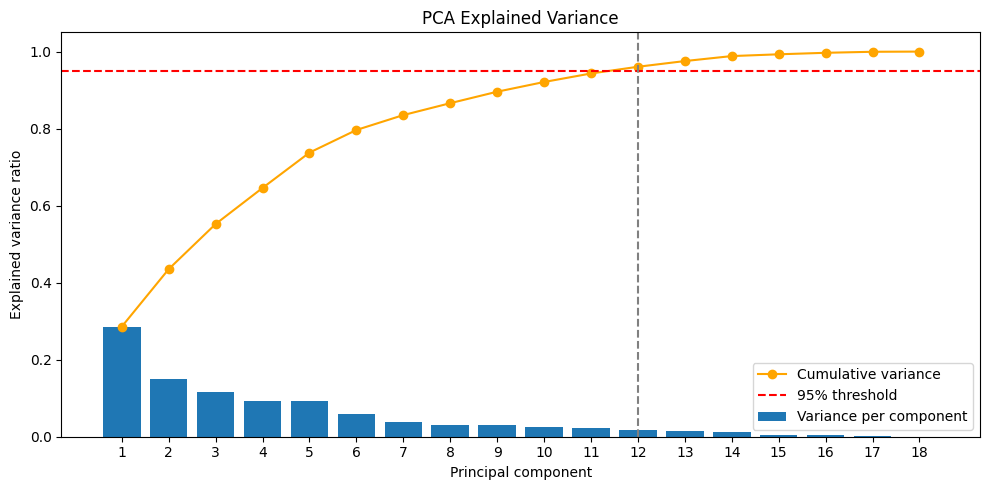

In [7]:
plt.figure(figsize=(10, 5))

plt.bar(components, variance, label="Variance per component")
plt.plot(components, cumulative_variance,marker="o", color="orange", label="Cumulative variance")

plt.axhline(0.95, color="red", linestyle="--", label="95% threshold")
plt.axvline(n_components, color="gray", linestyle="--")

plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("PCA Explained Variance")
plt.xticks(components)
plt.legend()
plt.tight_layout()
plt.savefig("../results/pca_explained_variance.png")
plt.show()

In [8]:
pca = PCA(n_components=int(n_components))

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Training shape:", X_train_pca.shape)
print("Testing shape:", X_test_pca.shape)

Training shape: (242, 12)
Testing shape: (61, 12)


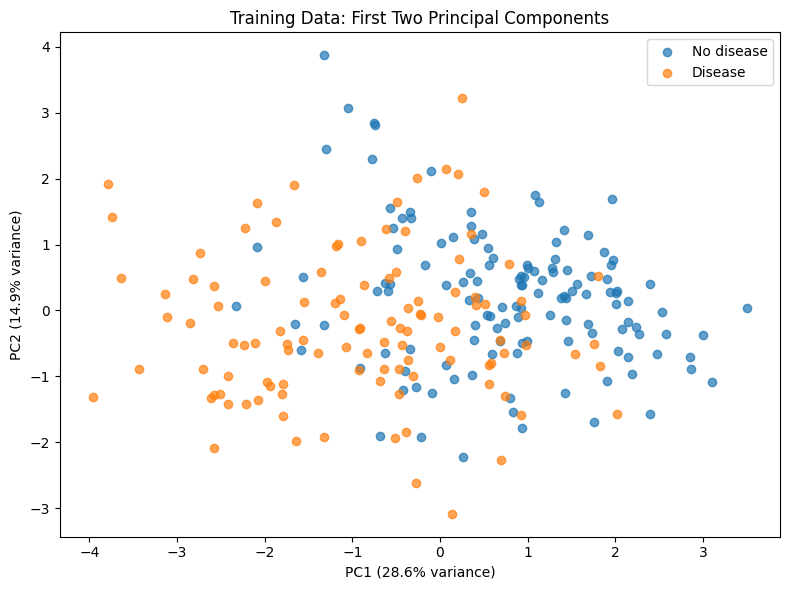

In [12]:
plot_data = pca_full.transform(X_train)

plt.figure(figsize=(8, 6))

for label, name in [(0, "No disease"), (1, "Disease")]:
    mask = y_train == label
    plt.scatter(plot_data[mask, 0],plot_data[mask, 1],label=name,alpha=0.7)

plt.xlabel(f"PC1 ({variance[0]:.1%} variance)")
plt.ylabel(f"PC2 ({variance[1]:.1%} variance)")
plt.title("Training Data: First Two Principal Components")
plt.legend()
plt.tight_layout()
plt.savefig("../results/pca_scatter.png")
plt.show()

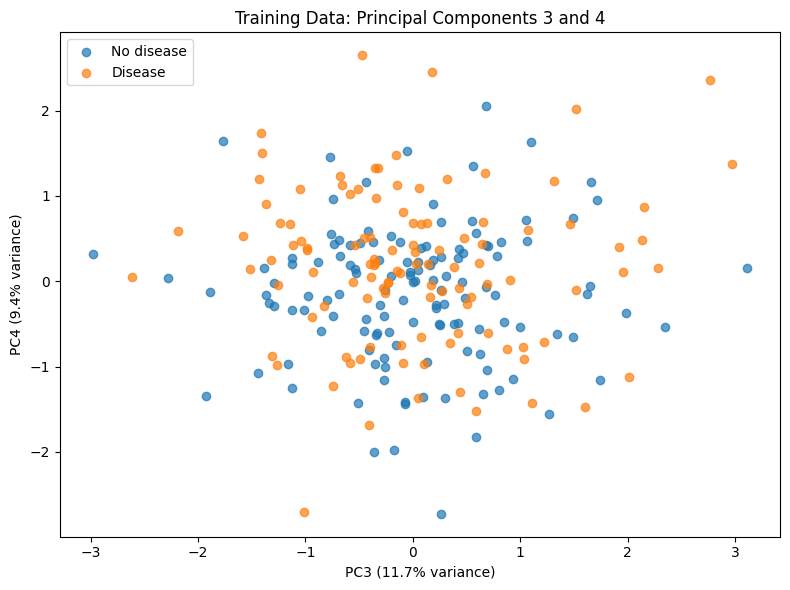

In [15]:
plot_data = pca_full.transform(X_train)

plt.figure(figsize=(8, 6))

for label, name in [(0, "No disease"), (1, "Disease")]:
    mask = y_train == label
    plt.scatter(plot_data[mask, 2],plot_data[mask, 3],label=name,alpha=0.7)

plt.xlabel(f"PC3 ({variance[2]:.1%} variance)")
plt.ylabel(f"PC4 ({variance[3]:.1%} variance)")
plt.title("Training Data: Principal Components 3 and 4")
plt.legend()
plt.tight_layout()
plt.show()

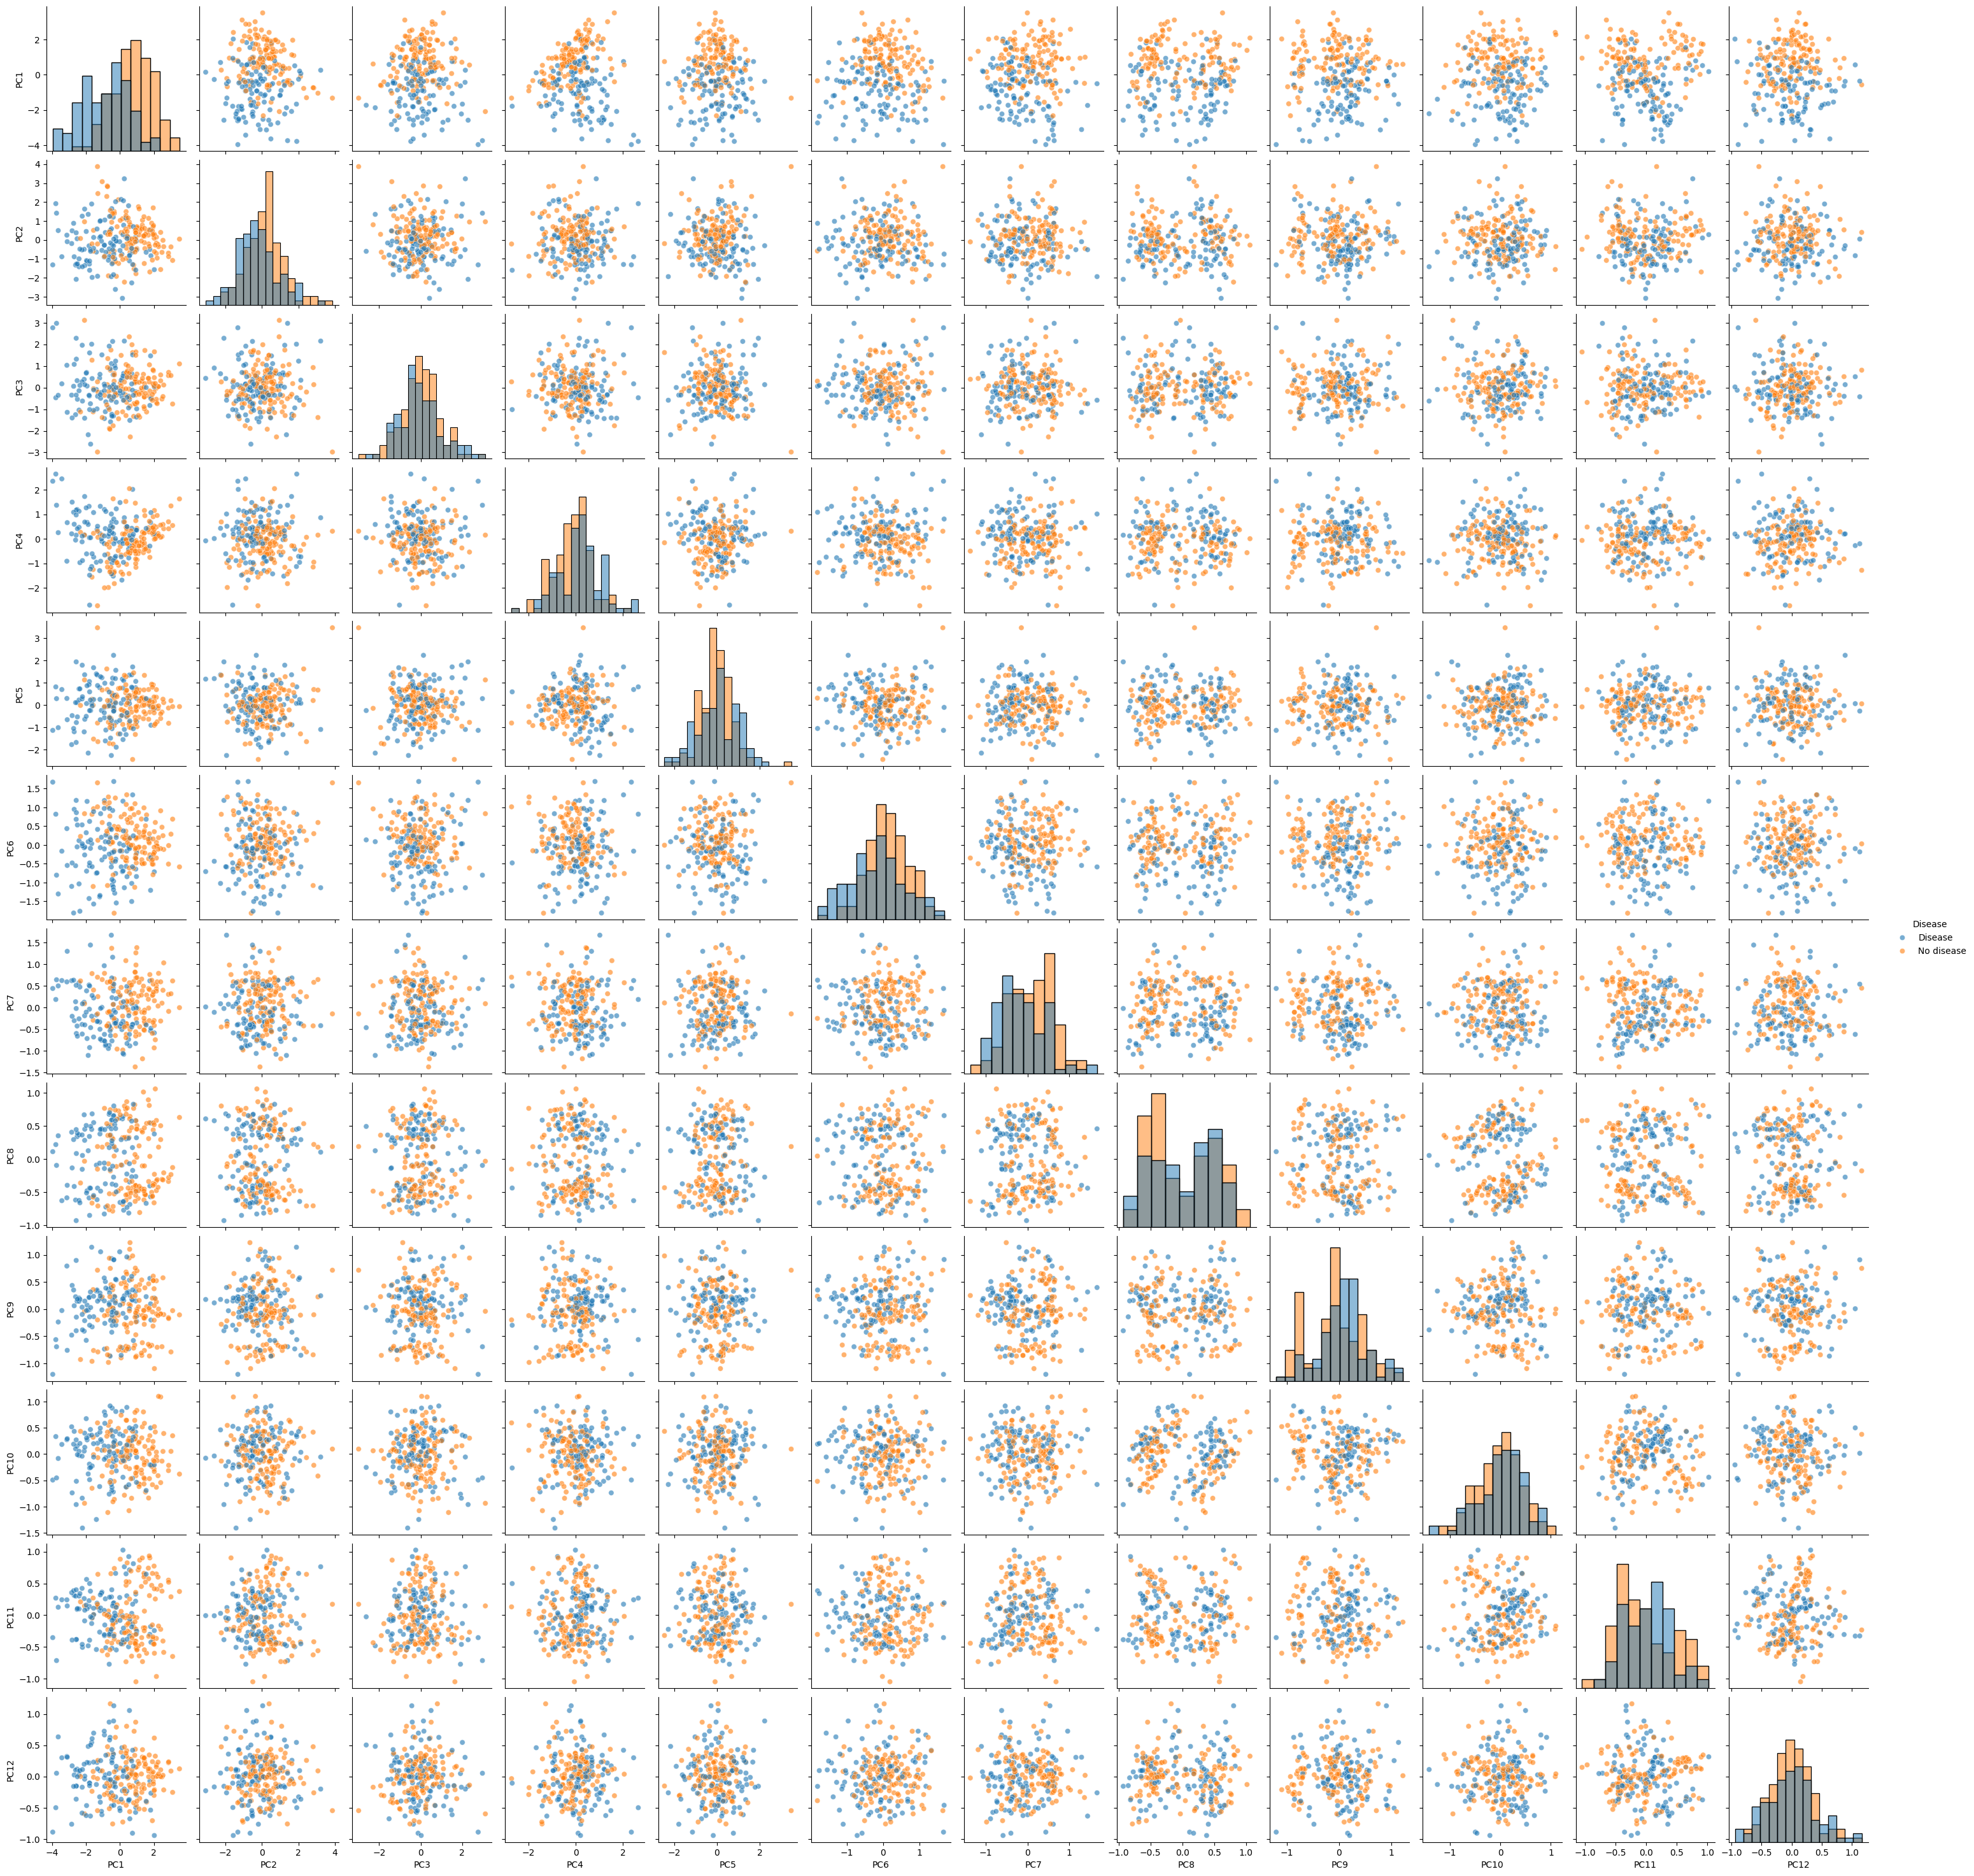

In [14]:
pca_df = pd.DataFrame(X_train_pca,columns=[f"PC{i + 1}" for i in range(n_components)])
pca_df["Disease"] = y_train.map({0: "No disease", 1: "Disease"})

g = sns.pairplot(pca_df,hue="Disease",diag_kind="hist",plot_kws={"alpha": 0.6})

g.savefig("../results/pca_pairplot.png")
plt.show()

## Save the PCA-transformed Data

In [10]:
pc_names = [f"PC{i + 1}" for i in range(n_components)]

pd.DataFrame(X_train_pca, columns=pc_names).to_csv("../data/X_train_pca.csv", index=False)
pd.DataFrame(X_test_pca, columns=pc_names).to_csv("../data/X_test_pca.csv", index=False)

pd.DataFrame({
    "component": components,
    "explained_variance_ratio": variance,
    "cumulative_variance": cumulative_variance
}).to_csv("../results/pca_variance.csv", index=False)